# 03 - Churn Prediction Modeling

**Goal:** predict which customers will place **no order in the next 120 days**.

Metrics to watch: **Recall** (don't miss customers who will leave) and **ROC-AUC** (ranking quality).

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
sys.path.append("../src")          # lets us reuse helper functions from src/pipeline.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)

In [2]:
from pipeline import load_and_clean, build_features, make_models, FEATURES, SEED
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, roc_curve, precision_recall_curve)
from sklearn.inspection import permutation_importance

feat = build_features(load_and_clean())
X, y = feat[FEATURES], feat["churn"]
print("Features used:", FEATURES)
y.value_counts(normalize=True).rename("share").to_frame()

[clean] raw=28,325 | duplicates=266 | missing customer=283 | cancellations=420 | clean=27,356
Features used: ['recency', 'frequency', 'monetary', 'aov', 'tenure_days', 'avg_gap_days', 'orders_last_90d', 'n_categories', 'discount_rate', 'return_rate', 'avg_review']


,share
churn,
1,0.51
0,0.49


## 1. Train / test split
80/20 split, **stratified** so both sets keep the same churn rate.

In [3]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"Train: {len(X_tr):,} | Test: {len(X_te):,}")

Train: 1,359 | Test: 340


## 2. Compare models

In [4]:
rows, fitted = [], {}
for name, model in make_models().items():
    model.fit(X_tr, y_tr)
    proba = model.predict_proba(X_te)[:, 1]
    pred = (proba >= 0.5).astype(int)
    rows.append({"Model": name, "Accuracy": accuracy_score(y_te, pred), "Precision": precision_score(y_te, pred),
                 "Recall": recall_score(y_te, pred), "F1": f1_score(y_te, pred), "ROC-AUC": roc_auc_score(y_te, proba)})
    fitted[name] = model
results = pd.DataFrame(rows).set_index("Model").round(3)
best_name = results["ROC-AUC"].idxmax()
print("Best model by ROC-AUC:", best_name)
results

Best model by ROC-AUC: Logistic Regression


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.87,0.94,0.79,0.86,0.94
Random Forest,0.86,0.93,0.79,0.85,0.93
Gradient Boosting,0.85,0.92,0.77,0.84,0.92


## 3. Confusion matrix and ROC curves

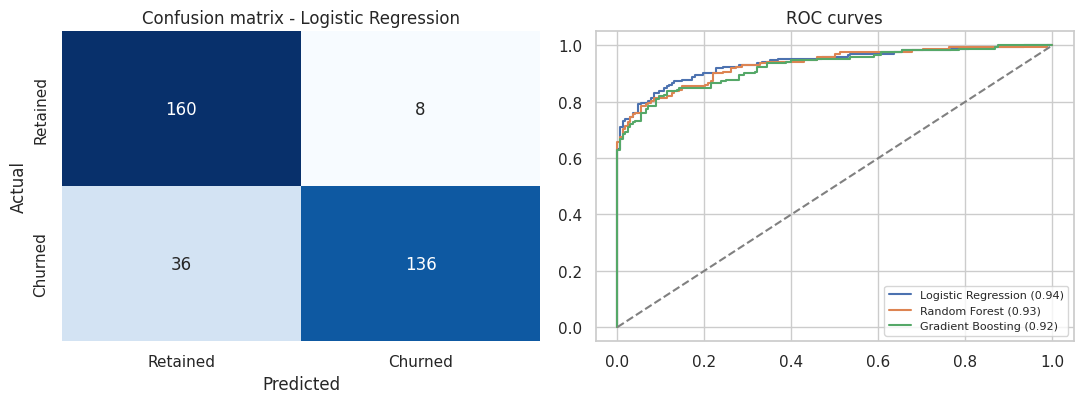

In [5]:
best = fitted[best_name]
pred = (best.predict_proba(X_te)[:, 1] >= 0.5).astype(int)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
sns.heatmap(confusion_matrix(y_te, pred), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0],
            xticklabels=["Retained", "Churned"], yticklabels=["Retained", "Churned"])
ax[0].set(title=f"Confusion matrix - {best_name}", xlabel="Predicted", ylabel="Actual")
for name, m in fitted.items():
    fpr, tpr, _ = roc_curve(y_te, m.predict_proba(X_te)[:, 1])
    ax[1].plot(fpr, tpr, label=f"{name} ({results.loc[name, 'ROC-AUC']:.2f})")
ax[1].plot([0, 1], [0, 1], "--", color="grey"); ax[1].legend(fontsize=8); ax[1].set(title="ROC curves")
plt.tight_layout()

## 4. Choosing the decision threshold
A threshold of 0.5 is a default, not a rule. If missing a churner costs more than contacting someone who
would have stayed, lower the threshold to gain recall.

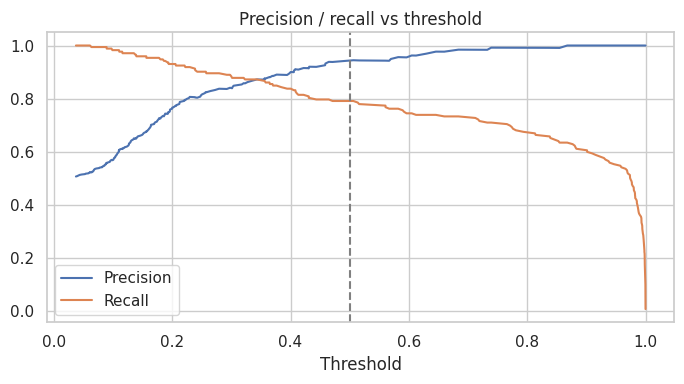

,precision,recall,customers flagged
threshold,,,
0.30,0.84,0.88,180
0.40,0.90,0.84,160
0.50,0.94,0.79,144
0.60,0.96,0.74,133
0.70,0.98,0.73,127


In [6]:
proba = best.predict_proba(X_te)[:, 1]
prec, rec, thr = precision_recall_curve(y_te, proba)
plt.figure(figsize=(7, 4))
plt.plot(thr, prec[:-1], label="Precision"); plt.plot(thr, rec[:-1], label="Recall")
plt.axvline(0.5, ls="--", color="grey"); plt.xlabel("Threshold"); plt.legend(); plt.title("Precision / recall vs threshold")
plt.tight_layout()
pd.DataFrame([{"threshold": t, "precision": precision_score(y_te, proba >= t), "recall": recall_score(y_te, proba >= t),
               "customers flagged": int((proba >= t).sum())} for t in [0.3, 0.4, 0.5, 0.6, 0.7]]).set_index("threshold").round(3)

## 5. What drives churn? (permutation importance)

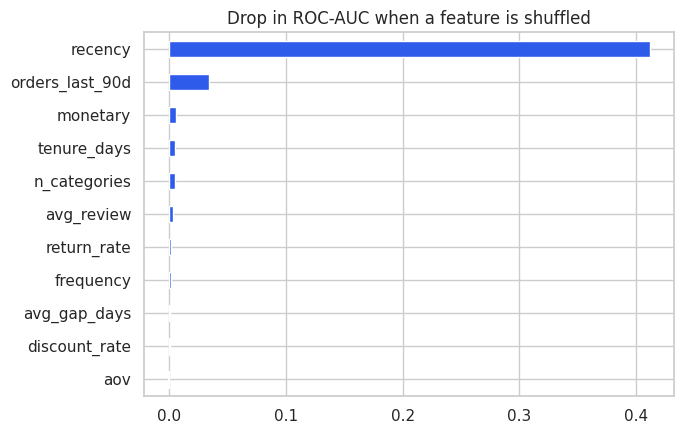

,importance
recency,0.41
orders_last_90d,0.03
monetary,0.01
tenure_days,0.01
n_categories,0.00


In [7]:
imp = permutation_importance(best, X_te, y_te, scoring="roc_auc", n_repeats=10, random_state=SEED)
imp_s = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
plt.figure(figsize=(7, 4.5)); imp_s.plot.barh(color="#2F5BEA")
plt.title("Drop in ROC-AUC when a feature is shuffled"); plt.tight_layout()
imp_s.sort_values(ascending=False).head(5).round(3).to_frame("importance")

### Key takeaways
- **Recency** (days since the last order) is by far the strongest churn signal; orders in the last 90 days comes next.
- Logistic Regression performs as well as or better than the tree models here - a good reminder to start with a baseline.
- Tune the threshold to the business cost of a missed churner, not to accuracy alone.

> Optional: `pip install shap` and the pipeline also saves a SHAP summary plot for tree models.

**Next:** `04_clv_and_recommendations.ipynb`